# 14-6. 증분 계산 확인

`model_selection` 모듈은 새 데이터가 들어오면 이미 계산한 앞쪽 origin을 다시 하지 않고, 데이터가 바뀐 위치 이후만 다시 계산한다(증분 계산). 이 노트북은 그 결과가 **처음부터 계산한 결과와 같은지**, 그리고 **다시 계산하는 양이 얼마나 줄어드는지**를 데이터가 바뀌는 여러 상황에서 확인한다.

- **적합**: 한 origin의 훈련 데이터에 모델 하나를 맞춰 4분기 앞을 예측하는 일. 계산 시간의 대부분이라 이 횟수로 줄어든 양을 잰다
- **증분의 원리**: origin마다 난수 상태와 오차 풀을 저장해 두고, 바뀐 관측이 처음 쓰이는 origin(`max(20, 바뀐 위치 - 4 + 1)`)부터 이어서 계산한다
- **확인 방법**: 같은 바뀐 데이터를 (1) 원래 데이터의 캐시에서 시작하는 증분 계산과 (2) 빈 캐시에서 처음부터 하는 계산으로 각각 돌려 결과를 비교했다(`python -m model_selection.checks.test_incremental <변수>`). 이 노트북은 그 실행 결과를 옮겨 적은 것이라 노트북 안에서 다시 계산하지는 않는다
- **대상 변수**: X2(로그 스케일 없음, 조합 24개)와 X5(로그 스케일 있음, 조합 48개)
- **시나리오**: 중간 구간만, 떨어진 관측만, 끝에 1분기·2분기 추가, 마지막 관측만 개정, 아주 앞쪽 관측 변경

## 1. 결과 데이터

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# `python -m model_selection.checks.test_incremental <변수>`의 실행 결과를 옮겨 적은 값이다(적합 횟수: 증분 / 처음부터).
# 시나리오마다 증분 결과와 처음부터 계산한 결과가 모든 열(crps, MSE, 적중, 폭, 하한, 상한, 중앙값, q50, 실제)에서 오차 1e-12 이내로 같았다.
NAMES = ["중간 구간만 바뀜 (2023Q1~Q4)", "사이사이만 바뀜 (2021Q2, 2023Q3, 2025Q1)", "끝에 1분기 추가", "끝에 2분기 추가", "마지막 관측만 바뀜", "앞쪽 관측이 바뀜 (2012Q1)"]
VARS = {"X2 (로그 불가, 조합 24개)": [(192, 492), (276, 492), (60, 504), (72, 516), (60, 492), (492, 492)],
        "X5 (로그 가능, 조합 48개)": [(384, 960), (552, 960), (120, 984), (144, 1008), (120, 960), (960, 960)]}
R = pd.DataFrame([{"변수": v, "시나리오": n, "증분 결과 = 처음부터 결과": True, "증분 적합 횟수": a, "처음부터 적합 횟수": b, "다시 계산한 비율(%)": a / b * 100}
                  for v, rows in VARS.items() for n, (a, b) in zip(NAMES, rows)])

## 2. 결과: 다시 계산한 비율

In [2]:
print("12개 경우 모두 증분 결과가 처음부터 계산한 결과와 같다 (오차 1e-12 이내)")
W = R.pivot(index="시나리오", columns="변수", values="다시 계산한 비율(%)").loc[list(R["시나리오"].unique())]
with pd.option_context("display.float_format", "{:,.0f}".format, "display.width", 200):
    display(W)

12개 경우 모두 증분 결과가 처음부터 계산한 결과와 같다 (오차 1e-12 이내)


변수,"X2 (로그 불가, 조합 24개)","X5 (로그 가능, 조합 48개)"
시나리오,,
중간 구간만 바뀜 (2023Q1~Q4),39,40
"사이사이만 바뀜 (2021Q2, 2023Q3, 2025Q1)",56,57
끝에 1분기 추가,12,12
끝에 2분기 추가,14,14
마지막 관측만 바뀜,12,12
앞쪽 관측이 바뀜 (2012Q1),100,100


In [3]:
T = R.set_index(["변수", "시나리오"])[["증분 적합 횟수", "처음부터 적합 횟수", "다시 계산한 비율(%)"]]
with pd.option_context("display.float_format", "{:,.1f}".format, "display.width", 200):
    display(T)

증분 적합 횟수  처음부터 적합 횟수  다시 계산한 비율(%)
변수                 시나리오                                                                 
X2 (로그 불가, 조합 24개) 중간 구간만 바뀜 (2023Q1~Q4)                   192         492          39.0
                   사이사이만 바뀜 (2021Q2, 2023Q3, 2025Q1)       276         492          56.1
                   끝에 1분기 추가                                60         504          11.9
                   끝에 2분기 추가                                72         516          14.0
                   마지막 관측만 바뀜                               60         492          12.2
                   앞쪽 관측이 바뀜 (2012Q1)                      492         492         100.0
X5 (로그 가능, 조합 48개) 중간 구간만 바뀜 (2023Q1~Q4)                   384         960          40.0
                   사이사이만 바뀜 (2021Q2, 2023Q3, 2025Q1)       552         960          57.5
                   끝에 1분기 추가                               120         984          12.2
                   끝에 2분기 추가                               144        1008          14.3
                   마지막 관측만 바뀜                              120         960          12.5
                   앞쪽 관측이 바뀜 (2012Q1)                      960         960         100.0

## 3. 그래프

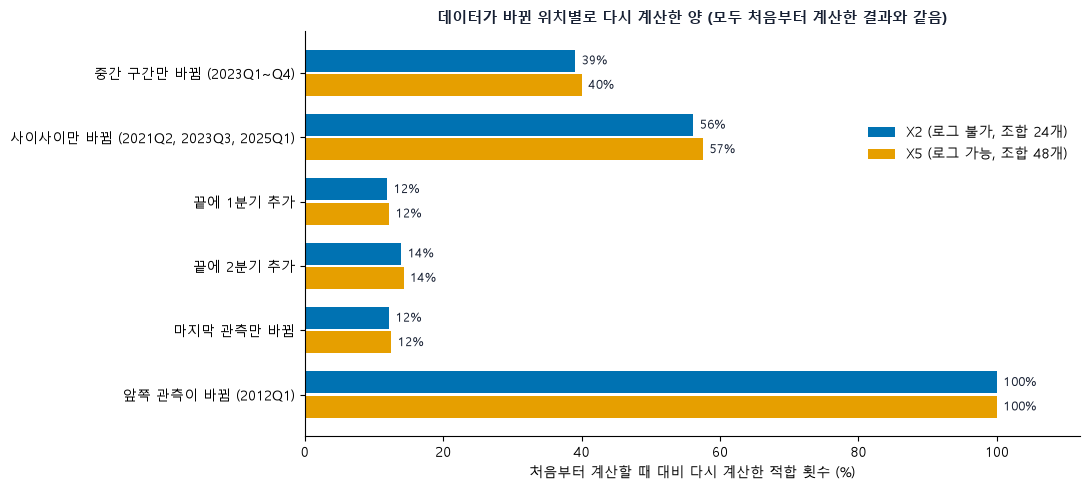

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
names = list(R["시나리오"].unique())
ys = np.arange(len(names))
for j, (v, c) in enumerate(zip(VARS.keys(), ["#0072B2", "#E69F00"])):
    s = R[R["변수"] == v].set_index("시나리오").loc[names, "다시 계산한 비율(%)"]
    bars = ax.barh(ys + (j - 0.5) * 0.38, s.values, height=0.34, color=c, label=v)
    for b_, x in zip(bars, s.values):
        ax.text(x + 1, b_.get_y() + b_.get_height() / 2, f"{x:.0f}%", va="center", fontsize=9, color="#172033")
ax.set_yticks(ys)
ax.set_yticklabels(names)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("처음부터 계산할 때 대비 다시 계산한 적합 횟수 (%)")
ax.set_title("데이터가 바뀐 위치별로 다시 계산한 양 (모두 처음부터 계산한 결과와 같음)", fontsize=11, fontweight="bold", color="#172033")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.8))
fig.tight_layout()
plt.show()

## 결론

- **결과는 항상 같다**: 두 변수, 시나리오 6개(12가지) 모두에서 증분 결과가 처음부터 계산한 결과와 모든 열이 오차 1e-12 이내로 같았다. 로그 스케일이 있는 변수(X5)도 같다.
- **다시 계산하는 양은 바뀐 위치에 따라 달라진다**(처음부터 계산할 때 대비 적합 횟수).
  - 끝에 분기를 추가하거나 마지막 관측만 바뀌면 12~14%다. 새 데이터가 뒤에 붙는 가장 흔한 상황이다.
  - 중간 구간이 바뀌면 39~40%, 떨어진 관측들이 바뀌면 56~57%다. 가장 이른 변경 위치부터 뒤쪽을 모두 다시 계산한다.
  - 아주 앞쪽(2012Q1)이 바뀌면 100%다. 그 뒤의 모든 origin이 영향을 받아 재사용할 것이 없다.
- **두 변수의 비율이 거의 같다**: 조합 수(24개, 48개)와 로그 스케일 여부는 비율에 영향이 없다.
- **한계**: 노트북에 적은 값은 `test_incremental`의 실행 결과를 옮긴 것이다. 코드를 바꾸면 `python -m model_selection.checks.test_incremental <변수>`로 다시 확인한다.
